# Linear SVM Baseline

This notebook trains a linear Support Vector Machine (`LinearSVC`) to predict the financial **Product**
(11 classes) from the cleaned CFPB complaint narrative. Linear SVMs are a classic strong baseline for
high-dimensional sparse text features such as TF-IDF.

- Features: the project's shared TF-IDF configuration (unigrams + bigrams, 100k features), fit on the training split only.
- Tuning: 3-fold stratified cross-validation on the training split, scored by **macro-F1** (the project's headline metric).
- Outputs: test-set metrics (`results/metrics/linear_svm.json`) and a row-normalized confusion matrix
  (`figures/linear_svm_confusion_matrix.png`).

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import LinearSVC

In [2]:
RANDOM_STATE = 42
MODEL_KEY = "linear_svm"

data_path = Path("../../data/processed/complaint_router_modeling_data.csv")
figures_dir = Path("../../figures")
metrics_dir = Path("../../results/metrics")

for folder in [figures_dir, metrics_dir]:
    folder.mkdir(parents=True, exist_ok=True)

SHORT_LABELS = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt/Credit Mgmt",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/Personal Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan",
}

## 1. Load the Modeling Data

The processed dataset already contains a fixed `split` column (80% train / 20% test, stratified by Product,
seed 42), so every model in the project is trained and evaluated on exactly the same complaints.
Only the columns needed for this task are loaded to save memory.

In [3]:
df = pd.read_csv(
    data_path,
    usecols=["Complaint ID", "Product", "clean_narrative", "split"],
)

print("Dataset shape:", df.shape)
print("Number of classes:", df["Product"].nunique())
print("Missing clean narratives:", df["clean_narrative"].isna().sum())

Dataset shape: (162500, 4)
Number of classes: 11
Missing clean narratives: 0


In [4]:
train = df[df["split"] == "train"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)

X_train_text, y_train = train["clean_narrative"], train["Product"]
X_test_text, y_test = test["clean_narrative"], test["Product"]

print(f"Training samples: {len(train):,}")
print(f"Testing samples: {len(test):,}")
print("Classes in train / test:", y_train.nunique(), "/", y_test.nunique())

Training samples: 130,000
Testing samples: 32,500
Classes in train / test: 11 / 11


## 2. TF-IDF Features

Narratives are converted to TF-IDF vectors with the shared project configuration: English stop words removed,
unigrams and bigrams, terms must appear in at least 5 complaints and in at most 90% of them, sublinear term
frequency, and the 100,000 most frequent terms kept. The vectorizer is fit on the training split only and then
applied to the test split.

In [5]:
vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.9,
    sublinear_tf=True,
    max_features=100_000,
)

start = time.perf_counter()
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)
tfidf_seconds = time.perf_counter() - start

print("Training TF-IDF shape:", X_train.shape)
print("Testing TF-IDF shape:", X_test.shape)
print(f"Vectorizing time: {tfidf_seconds:.1f} s")

Training TF-IDF shape: (130000, 100000)
Testing TF-IDF shape: (32500, 100000)
Vectorizing time: 50.1 s


## 3. Hyperparameter Tuning (3-Fold Cross-Validation)

`LinearSVC` handles the 11 products one-vs-rest: it trains one binary linear classifier per product and predicts
the product with the highest decision score. Two settings are tuned:

- `C`: inverse regularization strength (small = wider margin / stronger regularization), from 0.05 to 1.
- `class_weight`: `None` or `"balanced"` (errors on smaller products are up-weighted), which can help macro-F1.

That gives 5 × 2 = 10 configurations × 3 folds = 30 fits on the training split. The test split is not used here.
`max_iter` is raised from the default 1,000 to 5,000 so the solver converges for every configuration.

In [6]:
# Note: the TF-IDF vocabulary/IDF weights were fit on the full training split before CV, so each validation
# fold has a (negligible) influence on the IDF values. The test split is never involved.
param_grid = {
    "C": [0.05, 0.1, 0.25, 0.5, 1],
    "class_weight": [None, "balanced"],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(
    LinearSVC(max_iter=5000, random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=4,
    refit=True,
    verbose=1,
)

start = time.perf_counter()
grid.fit(X_train, y_train)
search_seconds = time.perf_counter() - start

print(f"Grid search time (30 CV fits + final refit): {search_seconds / 60:.1f} min")
print("Best parameters:", grid.best_params_)
print(f"Best CV macro-F1: {grid.best_score_:.4f}")

Fitting 3 folds for each of 10 candidates, totalling 30 fits


Grid search time (30 CV fits + final refit): 3.2 min
Best parameters: {'C': 0.25, 'class_weight': 'balanced'}
Best CV macro-F1: 0.7770


### Cross-Validation Results

Mean and standard deviation of macro-F1 across the 3 folds for every configuration (best first),
followed by the same scores arranged as a `C` × `class_weight` grid.

In [7]:
cv_results = pd.DataFrame(grid.cv_results_)

cv_table = pd.DataFrame({
    "C": cv_results["param_C"].astype(float),
    "class_weight": cv_results["param_class_weight"].astype(str),
    "mean_cv_macro_f1": cv_results["mean_test_score"],
    "std_cv_macro_f1": cv_results["std_test_score"],
    "mean_fit_seconds": cv_results["mean_fit_time"],
    "rank": cv_results["rank_test_score"],
}).sort_values("rank")

cv_table.round(4)

,C,class_weight,mean_cv_macro_f1,std_cv_macro_f1,mean_fit_seconds,rank
5,0.25,balanced,0.7770,0.0004,13.0292,1
3,0.10,balanced,0.7768,0.0004,11.1578,2
4,0.25,None,0.7750,0.0023,12.0201,3
6,0.50,None,0.7742,0.0010,13.9596,4
7,0.50,balanced,0.7739,0.0004,16.2725,5
1,0.05,balanced,0.7723,0.0003,10.9966,6
2,0.10,None,0.7693,0.0015,10.4184,7
8,1.00,None,0.7689,0.0005,19.7906,8
9,1.00,balanced,0.7674,0.0008,22.3589,9
0,0.05,None,0.7584,0.0009,11.1515,10


In [8]:
cv_table.pivot(index="C", columns="class_weight", values="mean_cv_macro_f1").round(4)

class_weight,None,balanced
C,,
0.05,0.7584,0.7723
0.10,0.7693,0.7768
0.25,0.7750,0.7770
0.50,0.7742,0.7739
1.00,0.7689,0.7674


## 4. Final Model

`GridSearchCV` automatically refits the best configuration on the **entire training split**.
The refit time is reported as the model's training time.

In [9]:
best_svm = grid.best_estimator_
train_seconds = grid.refit_time_

print("Final model:", best_svm)
print(f"Final fit time on {X_train.shape[0]:,} complaints: {train_seconds:.1f} s")
print("Solver iterations used:", int(np.max(best_svm.n_iter_)), "of", best_svm.max_iter)

Final model: LinearSVC(C=0.25, class_weight='balanced', max_iter=5000, random_state=42)
Final fit time on 130,000 complaints: 66.1 s
Solver iterations used: 19 of 5000


## 5. Test Set Evaluation

The tuned model is evaluated once on the held-out test split. Macro-F1 (the unweighted mean of the per-product
F1 scores) is the headline metric because it treats small products such as Prepaid Card as importantly as large
ones; accuracy and weighted-F1 are reported for reference.

In [10]:
y_pred = best_svm.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_macro_f1 = f1_score(y_test, y_pred, average="macro")
test_weighted_f1 = f1_score(y_test, y_pred, average="weighted")

print(f"Test Accuracy:    {test_accuracy:.4f}")
print(f"Test Macro-F1:    {test_macro_f1:.4f}")
print(f"Test Weighted-F1: {test_weighted_f1:.4f}")

Test Accuracy:    0.8056
Test Macro-F1:    0.7837
Test Weighted-F1: 0.8047


In [11]:
print(classification_report(y_test, y_pred, digits=3))

                                                         precision    recall  f1-score   support

                            Checking or savings account      0.773     0.804     0.788      4000
                                            Credit card      0.804     0.802     0.803      4000
    Credit reporting or other personal consumer reports      0.841     0.838     0.839      7000
                                        Debt collection      0.794     0.760     0.776      5000
                              Debt or credit management      0.561     0.453     0.501      1000
     Money transfer, virtual currency, or money service      0.800     0.802     0.801      3000
                                               Mortgage      0.901     0.931     0.916      2000
Payday loan, title loan, personal loan, or advance loan      0.660     0.725     0.691      1500
                                           Prepaid card      0.754     0.749     0.752      1000
                             

### Confusion Matrix

Rows are normalized so each row sums to 1: the diagonal is the recall for each product and the off-diagonal cells
show where that product's complaints are misrouted.

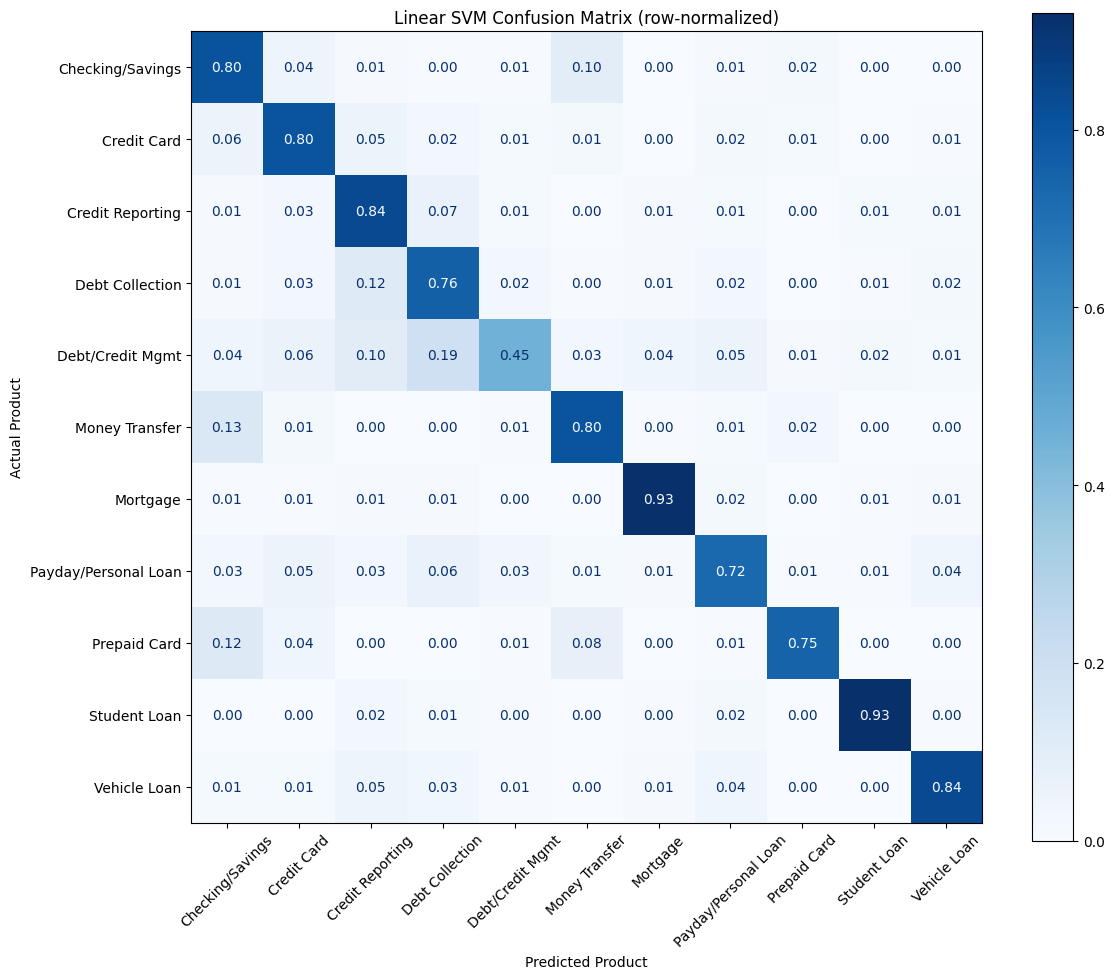

In [12]:
labels = best_svm.classes_
display_labels = [SHORT_LABELS[label] for label in labels]

fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=labels,
    display_labels=display_labels,
    normalize="true",
    values_format=".2f",
    xticks_rotation=45,
    cmap="Blues",
    ax=ax,
)

ax.set_title("Linear SVM Confusion Matrix (row-normalized)")
ax.set_xlabel("Predicted Product")
ax.set_ylabel("Actual Product")

plt.tight_layout()
plt.savefig(figures_dir / f"{MODEL_KEY}_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Most Influential Terms per Product

Each one-vs-rest classifier has its own weight vector. The terms with the largest positive weights push a
complaint most strongly toward that product (versus all other products).

In [13]:
feature_names = vectorizer.get_feature_names_out()
TOP_N = 10

top_terms = pd.DataFrame(
    {
        SHORT_LABELS[label]: feature_names[np.argsort(best_svm.coef_[i])[::-1][:TOP_N]]
        for i, label in enumerate(best_svm.classes_)
    },
    index=pd.RangeIndex(1, TOP_N + 1, name="rank"),
).T

top_terms

rank,1,2,3,4,5,6,7,8,9,10
Checking/Savings,bank,cd,debit card,overdraft,branch,chime,sofi,banking,deposit,usaa
Credit Card,card,synchrony,credit card,citi,capital,balance transfer,barclays,discover,rewards,comenity
Credit Reporting,equifax,experian,transunion,inquiries,report,inaccuracies,inquiry,lexisnexis,accounts,1681g
Debt Collection,debt,collection,collect,collections,owed,jefferson,transworld,associates,recovery,equipment
Debt/Credit Mgmt,debt relief,kikoff,americor,lexington,credit repair,bright,creditors,promised,tomoboost,lexington law
Money Transfer,zelle,paypal,coinbase,venmo,cashapp,transfer,crypto,wire,money,square
Mortgage,mortgage,heloc,escrow,foreclosure,appraisal,pennymac,home,newrez,modification,closing
Payday/Personal Loan,loan,affirm,personal loan,klarna,acima,solar,line credit,upstart,onemain,titlemax
Prepaid Card,card,prepaid,netspend,unemployment,way2go,wisely,edd,direct express,gift,money network
Student Loan,mohela,nelnet,navient,aidvantage,edfinancial,student,loans,school,forgiveness,ed financial


## 7. Save Metrics

Metrics are saved in the shared JSON format so `model_comparison.ipynb` can compare all models.

In [14]:
report = classification_report(y_test, y_pred, output_dict=True)

per_class = {
    label: {
        "precision": float(report[label]["precision"]),
        "recall": float(report[label]["recall"]),
        "f1": float(report[label]["f1-score"]),
        "support": int(report[label]["support"]),
    }
    for label in labels
}

metrics = {
    "model": MODEL_KEY,
    "display_name": "Linear SVM",
    "task": "product",
    "features": "TF-IDF 1-2 grams (100k)",
    "best_params": {
        "C": float(grid.best_params_["C"]),
        "class_weight": grid.best_params_["class_weight"],
    },
    "cv_macro_f1": float(grid.best_score_),
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1),
    "test_weighted_f1": float(test_weighted_f1),
    "per_class": per_class,
    "train_seconds": float(train_seconds),
    "n_train": int(X_train.shape[0]),
    "n_test": int(X_test.shape[0]),
}

metrics_path = metrics_dir / f"{MODEL_KEY}.json"
metrics_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")

print("Saved metrics to", metrics_path)

Saved metrics to ..\..\results\metrics\linear_svm.json


## 8. Comparison with the Other Baselines

The saved metrics files are loaded to compare the Linear SVM with Naive Bayes and Logistic Regression on the same
test split. (Models whose notebooks have not been run yet are skipped.)

In [15]:
compare_keys = ["naive_bayes", "complement_nb", "logistic_regression", MODEL_KEY]

rows = []
per_class_f1 = {}

for key in compare_keys:
    path = metrics_dir / f"{key}.json"
    if not path.exists():
        print(f"No metrics file yet for '{key}' - skipped.")
        continue

    m = json.loads(path.read_text(encoding="utf-8"))
    name = m.get("display_name", key)

    rows.append({
        "model": name,
        "cv_macro_f1": m.get("cv_macro_f1"),
        "test_accuracy": m["test_accuracy"],
        "test_macro_f1": m["test_macro_f1"],
        "test_weighted_f1": m["test_weighted_f1"],
        "train_seconds": m.get("train_seconds"),
    })
    per_class_f1[name] = {
        SHORT_LABELS.get(product, product): scores["f1"]
        for product, scores in m["per_class"].items()
    }

comparison = pd.DataFrame(rows).set_index("model")
comparison.round(4)

,cv_macro_f1,test_accuracy,test_macro_f1,test_weighted_f1,train_seconds
model,,,,,
Multinomial Naive Bayes,0.7190,0.7494,0.7230,0.7463,0.4646
Complement Naive Bayes,0.7210,0.7586,0.7211,0.7514,0.4857
Logistic Regression,0.7708,0.7978,0.7760,0.7955,62.0939
Linear SVM,0.7770,0.8056,0.7837,0.8047,66.0909


In [16]:
# Per-product test F1 for each model
pd.DataFrame(per_class_f1).round(3)

,Multinomial Naive Bayes,Complement Naive Bayes,Logistic Regression,Linear SVM
Checking/Savings,0.721,0.722,0.776,0.788
Credit Card,0.715,0.730,0.791,0.803
Credit Reporting,0.808,0.807,0.831,0.839
Debt Collection,0.729,0.740,0.766,0.776
Debt/Credit Mgmt,0.457,0.434,0.500,0.501
Money Transfer,0.690,0.752,0.790,0.801
Mortgage,0.878,0.877,0.914,0.916
Payday/Personal Loan,0.603,0.545,0.673,0.691
Prepaid Card,0.685,0.654,0.762,0.752
Student Loan,0.897,0.886,0.908,0.918


## Linear SVM Results Summary

- **Tuning.** The best configuration was **C = 0.25, class_weight = "balanced"** with a 3-fold CV macro-F1 of
  **0.777** (± 0.0004). C = 0.1 balanced was essentially tied (0.777). Balanced class weights helped most when
  regularization was strong (C = 0.05: 0.772 balanced vs 0.758 unbalanced) and made no difference at C ≥ 0.5.
  C = 1 was worse (0.769), so the grid brackets the optimum.
- **Test set.** Accuracy **80.6%**, macro-F1 **0.784**, weighted-F1 **0.805**, consistent with the CV estimate
  (0.777). The whole grid search took only 2.9 minutes. The final fit on all 130,000 training complaints took
  **81 s**, much longer than the ~7 s CV fits on 87k complaints. This is a solver effect: with `dual="auto"`,
  scikit-learn switches from the dual to the primal solver once there are more samples (130k) than features (100k).
- **vs. Logistic Regression and Naive Bayes.** The Linear SVM is the best model so far: macro-F1 0.784 vs 0.776
  for Logistic Regression and 0.723 / 0.721 for Multinomial / Complement NB (accuracy 80.6% vs 79.8% and
  74.9% / 75.9%). It matches or beats Logistic Regression on 10 of the 11 products; only Prepaid Card is slightly
  lower (0.752 vs 0.762). The gain over Logistic Regression is small (under 1 point), but it is larger than the
  fold-to-fold CV variation.
- **Strongest / weakest products.** Student Loan (F1 0.918) and Mortgage (0.916) are easiest. **Debt or credit
  management** is still the hardest (F1 0.501), followed by Payday/Personal Loan (0.691). The balanced class weights
  raised Debt/Credit Mgmt recall from 0.38 (Logistic Regression) to 0.45, at the cost of precision (0.72 → 0.56).
- **Most common confusions.** These are the same pairs as for Logistic Regression. Debt/Credit Mgmt goes to Debt
  Collection 19% of the time and to Credit Reporting 10%. Money Transfer goes to Checking/Savings 13%, Prepaid Card
  to Checking/Savings 12% (and to Money Transfer 8%), Debt Collection to Credit Reporting 12%, and Checking/Savings
  to Money Transfer 10%.
- **Top terms.** As with Logistic Regression, the strongest weights are company names and product vocabulary.
  Because each product gets its own one-vs-rest classifier, Debt/Credit Mgmt receives much more specific terms here
  (debt relief, credit repair, Kikoff, Americor, Lexington Law, Tomo Boost), and Credit Reporting picks up legal
  references such as "1681g" (a section of the Fair Credit Reporting Act).
- **Deployment choice.** Logistic Regression remains the model saved for the demo and the explainability notebook
  despite the SVM's small edge, because it gives class probabilities (top-3 products with confidence) and `LinearSVC`
  does not.